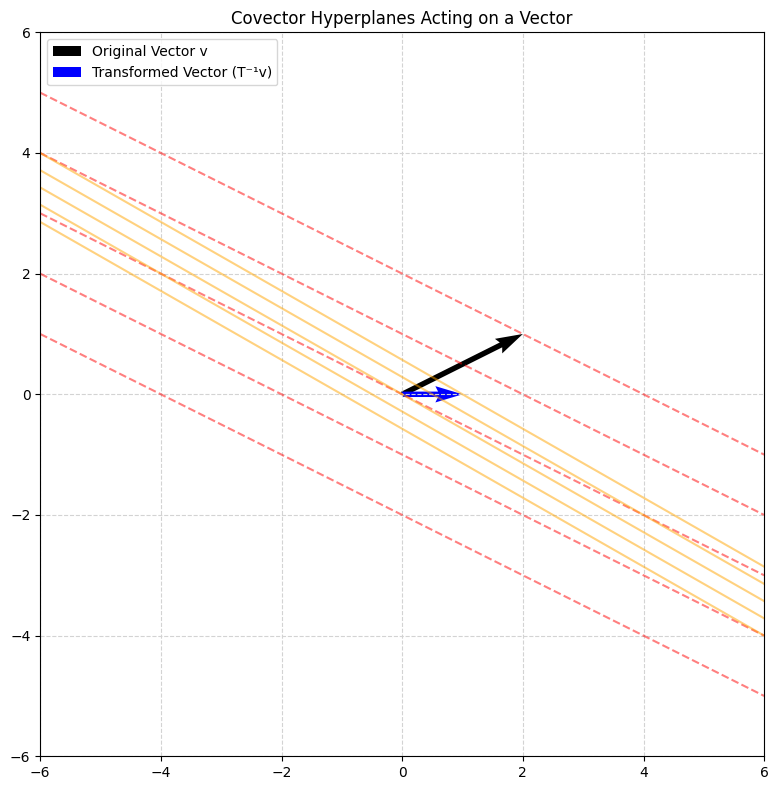

In [8]:
#contra variant transformation
import numpy as np
import matplotlib.pyplot as plt

# Define the original vector (could represent velocity)
v = np.array([2, 1])

# Define a covector (e.g., gradient), acting as a row vector
omega = np.array([1, 2])  # Covector acts via dot product

# Define transformation matrix (new basis)
T = np.array([[2, 1],
              [1, 3]])

# Transformations
T_inv = np.linalg.inv(T)
v_contra = T_inv @ v          # Contravariant transformation of vector
omega_co = omega @ T          # Covariant transformation of covector

# Evaluate inner product (should be the same before and after transformation)
original_action = omega @ v
transformed_action = omega_co @ v_contra

# Set up the plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', color='lightgray')
ax.set_title("Covector Hyperplanes Acting on a Vector")

# Plot original vector
ax.quiver(0, 0, *v, color='black', angles='xy', scale_units='xy', scale=1, label='Original Vector v')

# Plot covector hyperplanes (omega • x = const)
x_vals = np.linspace(-6, 6, 400)
for c in [-4, -2, 0, 2, 4]:
    # Line: omega[0] * x + omega[1] * y = c → y = (c - omega[0]*x)/omega[1]
    y_vals = (c - omega[0] * x_vals) / omega[1]
    ax.plot(x_vals, y_vals, 'r--', alpha=0.5)

# Plot vector after transformation
ax.quiver(0, 0, *v_contra, color='blue', angles='xy', scale_units='xy', scale=1, label='Transformed Vector (T⁻¹v)')

# Plot transformed covector hyperplanes (omega_co • x = const)
for c in [-4, -2, 0, 2, 4]:
    y_vals_transformed = (c - omega_co[0] * x_vals) / omega_co[1]
    ax.plot(x_vals, y_vals_transformed, 'orange', alpha=0.5)

# Add legend and show
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


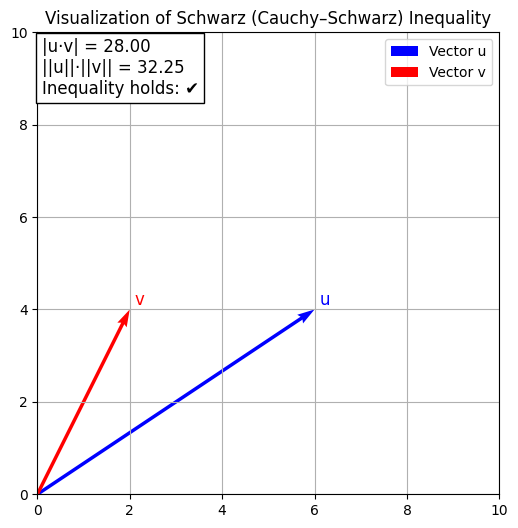

In [9]:
#Schwarz’s Inequality
import numpy as np
import matplotlib.pyplot as plt

vec1 = list(map(float, input("First vector (x,y): ").split(',')))
vec2 = list(map(float, input("Second vector (x,y): ").split(',')))

# Define two 2D vectors
u = np.array(vec1)
v = np.array(vec2)

# Compute dot product and magnitudes
dot_product = np.dot(u, v)
norm_u = np.linalg.norm(u)
norm_v = np.linalg.norm(v)
rhs = norm_u * norm_v

# Plot setup
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect('equal')
ax.grid(True)
ax.set_title("Visualization of Schwarz (Cauchy–Schwarz) Inequality")

# Plot vectors u and v
ax.quiver(0, 0, *u, angles='xy', scale_units='xy', scale=1, color='blue', label='Vector u')
ax.quiver(0, 0, *v, angles='xy', scale_units='xy', scale=1, color='red', label='Vector v')

# Add labels
ax.text(*(u + 0.1), 'u', color='blue', fontsize=12)
ax.text(*(v + 0.1), 'v', color='red', fontsize=12)

# Show the inequality as text
text = f"|u·v| = {abs(dot_product):.2f}\n||u||·||v|| = {rhs:.2f}\n"
text += "Inequality holds: " + ("✔️" if abs(dot_product) <= rhs else "Nope")

ax.text(0.09, 8.67, text, fontsize=12, bbox=dict(facecolor='white', edgecolor='black'))

ax.legend()
plt.show()


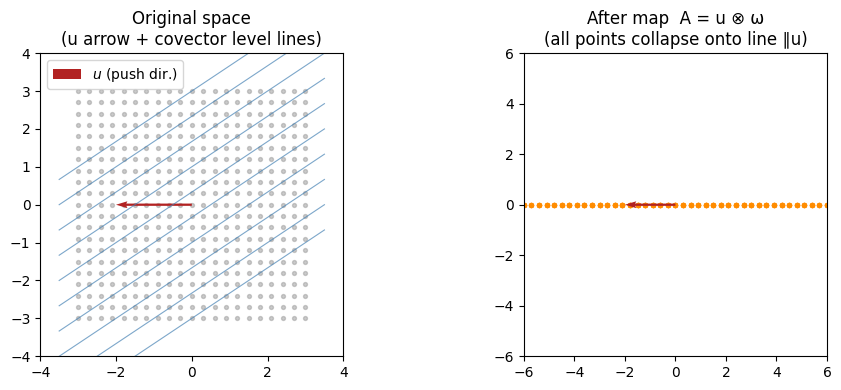

Vector u: [-2.  0.]
Covector omega: [ 1.  -1.5]
Outer‑product matrix A = u ⊗ ω:
 [[-2.  3.]
 [ 0. -0.]]


In [7]:
"""-----------OUTER PRODUCTS-----------"""
import numpy as np
import matplotlib.pyplot as plt

# --- EDIT THESE VECTORS IF YOU LIKE ---------------------------------
u      = np.array([-2.0, 0])   # 2‑D vector  (push direction, lives in tangent space)
omega  = np.array([1.0, -1.5])  # 2‑D covector (measurement direction, lives in cotangent space)
# --------------------------------------------------------------------

# Outer‑product matrix A = u ⊗ omega  (rank‑1 linear map)
A = np.outer(u, omega)          # shape (2,2)

# Build a grid of sample points to show the transformation
xs = np.linspace(-3, 3, 21)
ys = np.linspace(-3, 3, 21)
grid_x, grid_y = np.meshgrid(xs, ys)
pts = np.vstack([grid_x.ravel(), grid_y.ravel()])     # shape 2×N

# Apply outer‑product map to every point
mapped = A @ pts

# ------------------------------------------------------------ plotting
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharex=False, sharey=False)

# ---- panel (a) : original space with u‑arrow and covector lines ----
ax[0].scatter(pts[0], pts[1], s=8, color="#999", alpha=0.5)
ax[0].quiver(0, 0, u[0], u[1], angles='xy', scale_units='xy', scale=1, color="firebrick",
             label=r"$u$ (push dir.)", linewidth=2)

# draw several level‑lines omega(x)=c
c_vals = np.linspace(-4.5, 4.5, 10)
xx = np.linspace(-3.5, 3.5, 200)
for c in c_vals:
    # omega = [a,b]; line a*x + b*y = c  ⇒ y = (c - a*x)/b
    if abs(omega[1]) > 1e-9:
        yy = (c - omega[0]*xx) / omega[1]
        ax[0].plot(xx, yy, color="steelblue", linewidth=0.8, alpha=0.7)
ax[0].set_title("Original space\n(u arrow + covector level lines)")
ax[0].set_aspect('equal')
ax[0].set_xlim(-4, 4)
ax[0].set_ylim(-4, 4)
ax[0].legend()

# ---- panel (b) : transformed points after outer product ------------
ax[1].scatter(mapped[0], mapped[1], s=8, color="darkorange", alpha=0.8)
ax[1].quiver(0, 0, u[0], u[1], angles='xy', scale_units='xy', scale=1, color="firebrick",
             linewidth=2)
ax[1].set_title("After map  A = u ⊗ ω\n(all points collapse onto line ∥u)")
ax[1].set_aspect('equal')
ax[1].set_xlim(-6, 6)
ax[1].set_ylim(-6, 6)

plt.tight_layout()
plt.show()

print("Vector u:", u)
print("Covector omega:", omega)
print("Outer‑product matrix A = u ⊗ ω:\n", A)


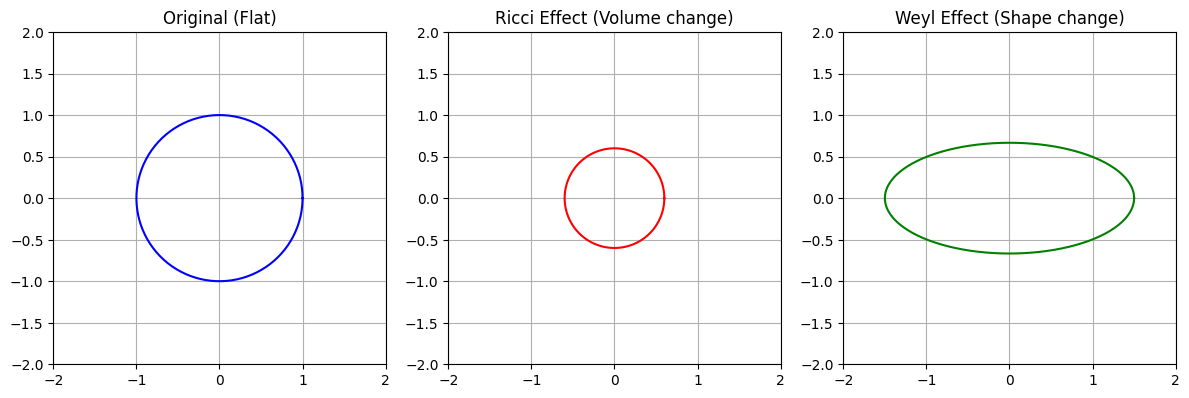

In [6]:
"""-----------Ricci Vs Weyl Vs Riemann-----------"""
import numpy as np
import matplotlib.pyplot as plt

# Create a cloud of points (dust particles in 2D)
N = 200
angles = np.linspace(0, 2*np.pi, N)
x = np.cos(angles)
y = np.sin(angles)

def apply_ricci(x, y, factor=0.7):
    """Shrink or expand isotropically (volume change)."""
    return factor * x, factor * y

def apply_weyl(x, y, stretch=1.3):
    """Stretch in x, squeeze in y (shape change, no volume change)."""
    return stretch * x, (1/stretch) * y

# Plot original, Ricci, and Weyl effects
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Original cloud
axes[0].plot(x, y, 'b')
axes[0].set_title("Original (Flat)")
axes[0].set_aspect("equal")

# Ricci curvature effect (shrink cloud)
xr, yr = apply_ricci(x, y, factor=0.6)
axes[1].plot(xr, yr, 'r')
axes[1].set_title("Ricci Effect (Volume change)")
axes[1].set_aspect("equal")

# Weyl curvature effect (tidal distortion)
xw, yw = apply_weyl(x, y, stretch=1.5)
axes[2].plot(xw, yw, 'g')
axes[2].set_title("Weyl Effect (Shape change)")
axes[2].set_aspect("equal")

for ax in axes:
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.grid(True)

plt.tight_layout()
plt.show()


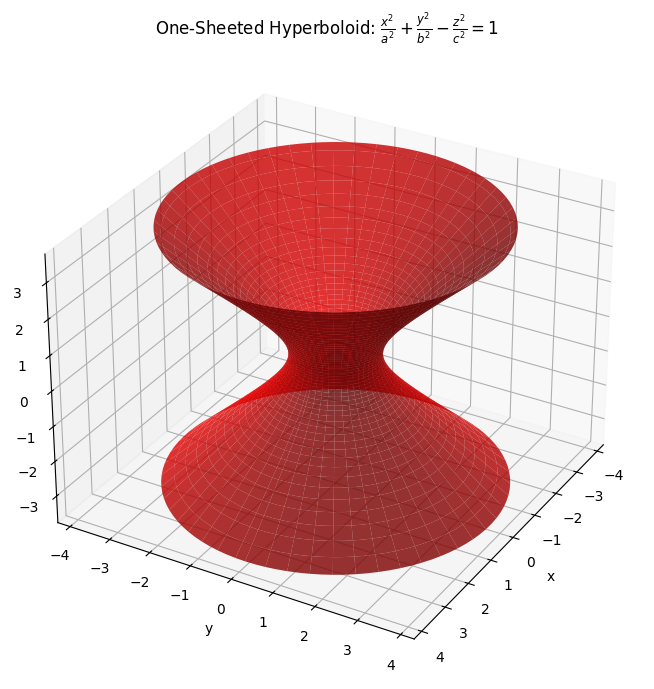

In [10]:
"""----------Loci----------"""
import numpy as np
import matplotlib.pyplot as plt

# Parameters
a = 1  # x and y axis scaling
c = 1  # z axis scaling
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(-2, 2, 100)
U, V = np.meshgrid(u, v)

# Parametric equations for one-sheeted hyperboloid
X = a * np.cosh(V) * np.cos(U)
Y = a * np.cosh(V) * np.sin(U)
Z = c * np.sinh(V)

# Plotting
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, color='red', alpha=0.8)

# Labels and aesthetics
ax.set_title("One-Sheeted Hyperboloid: $\\frac{x^2}{a^2} + \\frac{y^2}{b^2} - \\frac{z^2}{c^2} = 1$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.view_init(elev=30, azim=30)
plt.tight_layout()
plt.savefig("one_sheeted_hyperboloid.png", dpi=300)
plt.show()


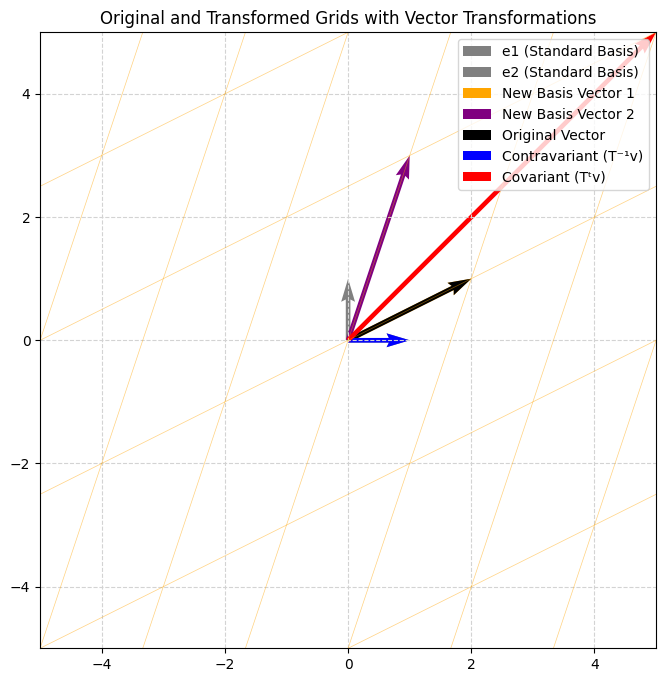

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Set up original basis vectors
e1 = np.array([1, 0])
e2 = np.array([0, 1])
standard_basis = np.column_stack((e1, e2))

# Define a vector in standard basis
v = np.array([2, 1])

# Define a linear transformation (new basis)
T = np.array([[2, 1],
              [1, 3]])  # New basis matrix (columns are the new basis vectors)

# Contravariant transformation (vector in new coordinates)
T_inv = np.linalg.inv(T)
v_contra = T_inv @ v

# Covariant transformation (e.g. gradient or dual)
v_co = T.T @ v

# Setup plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', color='lightgray')
ax.set_title("Original and Transformed Grids with Vector Transformations")

# Plot original basis vectors
ax.quiver(0, 0, *e1, color='gray', scale=1, scale_units='xy', angles='xy', label='e1 (Standard Basis)')
ax.quiver(0, 0, *e2, color='gray', scale=1, scale_units='xy', angles='xy', label='e2 (Standard Basis)')

# Plot new basis vectors (columns of T)
ax.quiver(0, 0, *T[:, 0], color='orange', scale=1, scale_units='xy', angles='xy', label="New Basis Vector 1")
ax.quiver(0, 0, *T[:, 1], color='purple', scale=1, scale_units='xy', angles='xy', label="New Basis Vector 2")

# Plot original vector
ax.quiver(0, 0, *v, color='black', angles='xy', scale_units='xy', scale=1, label='Original Vector')

# Plot contravariant transformation
ax.quiver(0, 0, *v_contra, color='blue', angles='xy', scale_units='xy', scale=1, label='Contravariant (T⁻¹v)')

# Plot covariant transformation
ax.quiver(0, 0, *v_co, color='red', angles='xy', scale_units='xy', scale=1, label='Covariant (Tᵗv)')

# Draw transformed grid
grid_range = np.arange(-5, 6, 1)
for x in grid_range:
    points = np.array([T @ [x, y] for y in grid_range])
    ax.plot(points[:, 0], points[:, 1], color='orange', linewidth=0.5, alpha=0.5)

for y in grid_range:
    points = np.array([T @ [x, y] for x in grid_range])
    ax.plot(points[:, 0], points[:, 1], color='orange', linewidth=0.5, alpha=0.5)

# Legend and show
ax.legend()
plt.savefig("co-contra_variant_vectors.png",dpi=900)
plt.show()


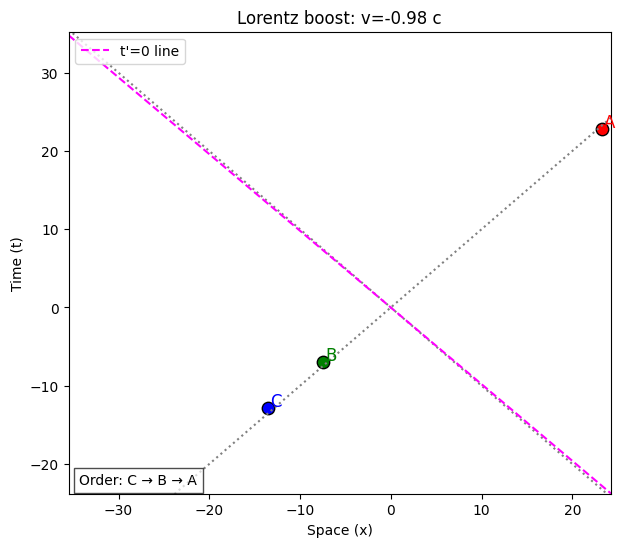

C:\Users\Abdul\AppData\Local\Temp\ipykernel_19596\2259784009.py:27: RuntimeWarning: invalid value encountered in divide
  V_norm = V / np.linalg.norm(V, axis=-1, keepdims=True)


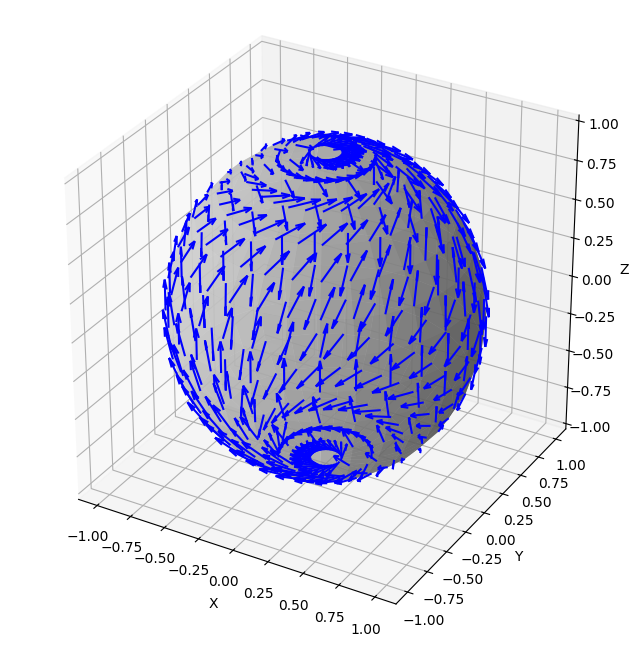

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Spherical mesh
theta = np.linspace(0.1, np.pi - 0.1, 15)   # avoid poles (cot blows up)
phi = np.linspace(0, 2*np.pi, 30)
theta, phi = np.meshgrid(theta, phi)

# Sphere coordinates
x = np.sin(theta) * np.cos(phi)
y = np.sin(theta) * np.sin(phi)
z = np.cos(theta)

# Unit vectors in Cartesian basis
e_theta = np.stack([np.cos(theta)*np.cos(phi),
                    np.cos(theta)*np.sin(phi),
                   -np.sin(theta)], axis=-1)

e_phi = np.stack([-np.sin(phi),
                  np.cos(phi),
                  np.zeros_like(phi)], axis=-1)

# Vector field V = sin(phi) e_theta - cot(theta) sin(phi) e_phi
V = np.sin(phi)[..., None]*e_theta - ((np.cos(theta)/np.sin(theta))[..., None] * np.sin(phi)[..., None] * e_phi)

# Normalize for plotting clarity
V_norm = V / np.linalg.norm(V, axis=-1, keepdims=True)

# Plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot sphere surface (transparent)
ax.plot_surface(x, y, z, color='lightgray', alpha=0.7, edgecolor='none')

# Plot vector field
ax.quiver(x, y, z, V_norm[...,0], V_norm[...,1], V_norm[...,2], length=0.2, normalize=True, color="blue")

ax.set_box_aspect([1,1,1])
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.savefig("Killing Vectors for Shwartz Solution",dpi=600)
plt.show()


In [8]:
import numpy as np
import plotly.graph_objects as go

# Grid
theta = np.linspace(0.2, np.pi-0.2, 20)
phi = np.linspace(0, 2*np.pi, 40)
theta, phi = np.meshgrid(theta, phi)

# Sphere coordinates
x = np.sin(theta) * np.cos(phi)
y = np.sin(theta) * np.sin(phi)
z = np.cos(theta)

# Unit vectors in Cartesian
e_theta = np.stack([np.cos(theta)*np.cos(phi),
                    np.cos(theta)*np.sin(phi),
                   -np.sin(theta)], axis=-1)
e_phi = np.stack([-np.sin(phi),
                  np.cos(phi),
                  np.zeros_like(phi)], axis=-1)

# Vector field
V = np.sin(phi)[..., None]*e_theta - ((np.cos(theta)/np.sin(theta))[..., None] * np.sin(phi)[..., None] * e_phi)

# Normalize for plotting clarity
V = V / np.linalg.norm(V, axis=-1, keepdims=True)

# Flatten arrays for quiver plotting
x, y, z = x.flatten(), y.flatten(), z.flatten()
u, v, w = V[...,0].flatten(), V[...,1].flatten(), V[...,2].flatten()

# Create interactive 3D figure
fig = go.Figure()

# Sphere surface
fig.add_trace(go.Surface(x=np.sin(theta)*np.cos(phi),
                         y=np.sin(theta)*np.sin(phi),
                         z=np.cos(theta),
                         opacity=0.3, showscale=False))

# Vector field arrows
fig.add_trace(go.Cone(x=x, y=y, z=z, u=u, v=v, w=w,
                      colorscale="Blues", sizemode="absolute", sizeref=0.3))

fig.update_layout(scene=dict(aspectmode="data"))
fig.show()


C:\Users\Abdul\AppData\Local\Temp\ipykernel_19596\671647983.py:26: RuntimeWarning: invalid value encountered in divide
  V = V / np.linalg.norm(V, axis=-1, keepdims=True)


C:\Users\Abdul\AppData\Local\Temp\ipykernel_19596\3907024438.py:24: RuntimeWarning:

invalid value encountered in divide

D:\Apps\GItHubRebo\mathematics_physics_python\.venv\Lib\site-packages\pyvista\jupyter\notebook.py:56: UserWarning:

Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.



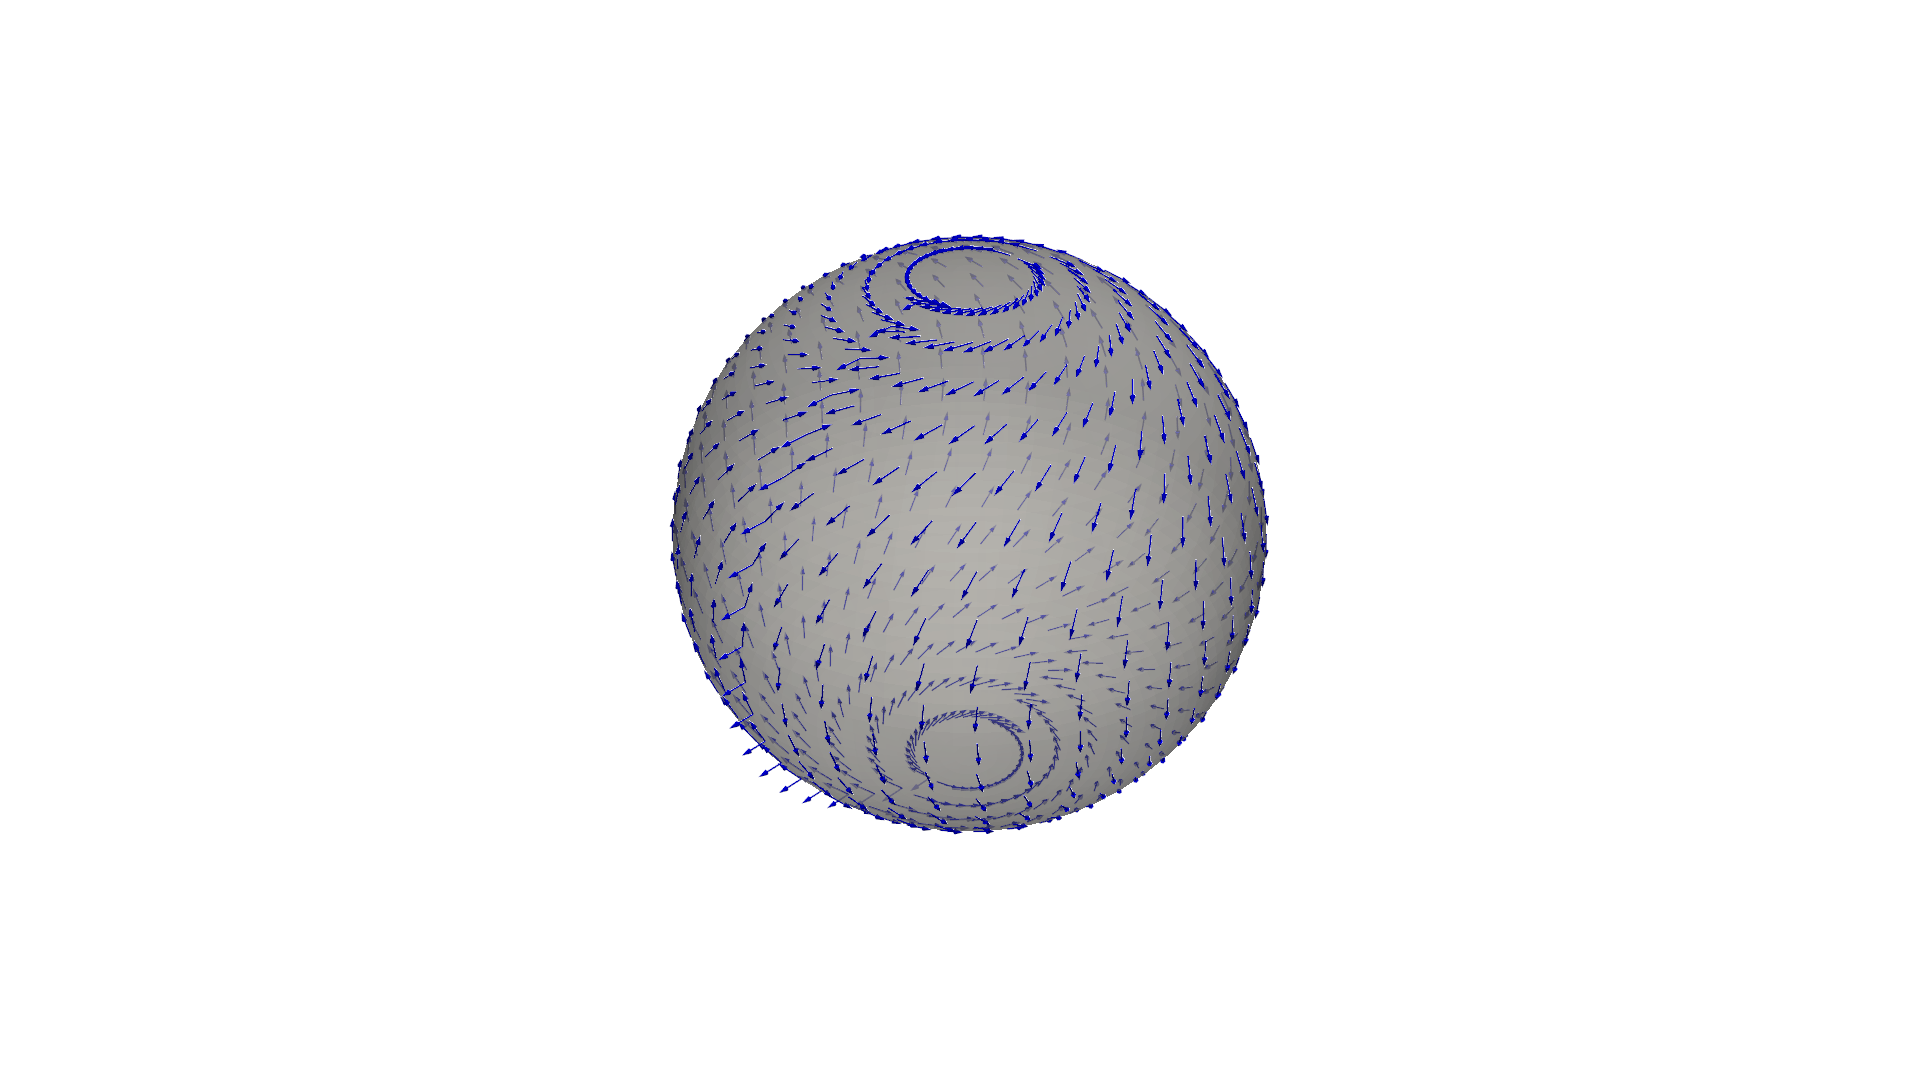

pyvista_ndarray([[[255, 255, 255],
                  [255, 255, 255],
                  [255, 255, 255],
                  ...,
                  [255, 255, 255],
                  [255, 255, 255],
                  [255, 255, 255]],

                 [[255, 255, 255],
                  [255, 255, 255],
                  [255, 255, 255],
                  ...,
                  [255, 255, 255],
                  [255, 255, 255],
                  [255, 255, 255]],

                 [[255, 255, 255],
                  [255, 255, 255],
                  [255, 255, 255],
                  ...,
                  [255, 255, 255],
                  [255, 255, 255],
                  [255, 255, 255]],

                 ...,

                 [[255, 255, 255],
                  [255, 255, 255],
                  [255, 255, 255],
                  ...,
                  [255, 255, 255],
                  [255, 255, 255],
                  [255, 255, 255]],

                 [[255, 255, 255],
  

In [13]:
import numpy as np
import pyvista as pv

# Grid
theta = np.linspace(0.2, np.pi-0.2, 20)
phi = np.linspace(0, 2*np.pi, 40)
theta, phi = np.meshgrid(theta, phi)

# Sphere coords
x = np.sin(theta) * np.cos(phi)
y = np.sin(theta) * np.sin(phi)
z = np.cos(theta)

# Unit vectors
e_theta = np.stack([np.cos(theta)*np.cos(phi),
                    np.cos(theta)*np.sin(phi),
                   -np.sin(theta)], axis=-1)
e_phi = np.stack([-np.sin(phi),
                  np.cos(phi),
                  np.zeros_like(phi)], axis=-1)

# Vector field
V = np.sin(phi)[..., None]*e_theta - ((np.cos(theta)/np.sin(theta))[..., None] * np.sin(phi)[..., None] * e_phi)
V = V / np.linalg.norm(V, axis=-1, keepdims=True)

# Flatten
points = np.c_[x.flatten(), y.flatten(), z.flatten()]
vectors = np.c_[V[...,0].flatten(), V[...,1].flatten(), V[...,2].flatten()]

# Build PyVista dataset
pdata = pv.PolyData(points)
pdata["vectors"] = vectors

# Create arrows from vectors
arrows = pdata.glyph(orient="vectors", scale=False, factor=0.1)

# Plot
plotter = pv.Plotter()
sphere = pv.Sphere(radius=1.0, theta_resolution=60, phi_resolution=60)
plotter.add_mesh(sphere, color="lightgray", opacity=0.6)
plotter.add_mesh(arrows, color="blue")

# Save screenshot with chosen resolution (e.g., Full HD)
plotter.show(screenshot="SKillingVectorFieldShwartz.png", window_size=[1920, 1080])
plotter.screenshot("SKillingVectorFieldShwartz.png", window_size=[3840, 2160])  # 4K image


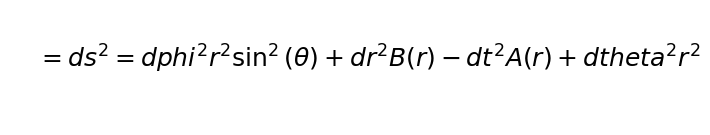

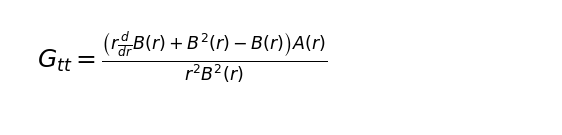

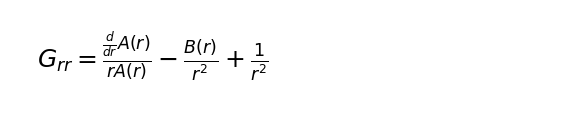

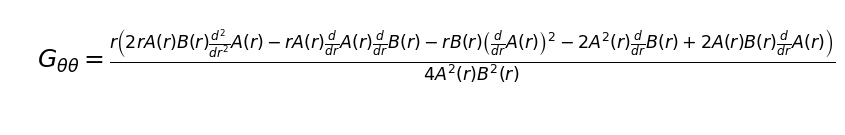

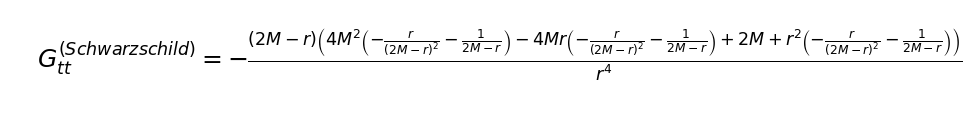

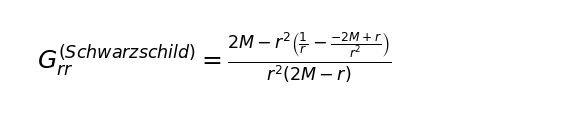

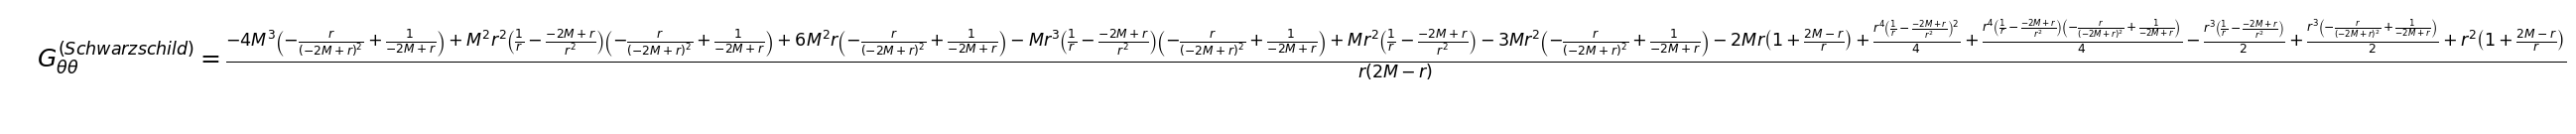

In [2]:
# schwarzschild_symbolic.py
import sympy as sp
import matplotlib.pyplot as plt

'''========= 1. Setup symbols ========='''

r, t, th, ph = sp.symbols('r t theta phi')

M = sp.symbols('M', real=True)   # mass parameter
A = sp.Function('A')(r)
B = sp.Function('B')(r)

coords = (t, r, th, ph)

# Metric: ds^2 = -A(r) dt^2 + B(r) dr^2 + r^2 dθ^2 + r^2 sin(θ)^2 dΦ^2
g = sp.diag(-A, B, r**2, r**2 * sp.sin(th)**2)
g_inv = g.inv()

# dimension
n = 4

'''========= 2. Christoffel symbols ========='''

Gamma = sp.MutableDenseNDimArray([[[0]*n for _ in range(n)] for __ in range(n)])
for i in range(n):
    for j in range(n):
        for k in range(n):
            s = 0
            for l in range(n):
                s += g_inv[i, l] * (sp.diff(g[l, k], coords[j])
                                    + sp.diff(g[l, j], coords[k])
                                    - sp.diff(g[j, k], coords[l]))
            Gamma[i, j, k] = sp.simplify(sp.Rational(1, 2) * s)

# === 3. Ricci tensor ===
R = sp.MutableDenseNDimArray([[0]*n for _ in range(n)])
for i in range(n):
    for j in range(n):
        expr = 0
        for k in range(n):
            expr += sp.diff(Gamma[k, i, j], coords[k]) - sp.diff(Gamma[k, i, k], coords[j])
            for l in range(n):
                expr += Gamma[k, i, j]*Gamma[l, k, l] - Gamma[k, i, l]*Gamma[l, j, k]
        R[i, j] = sp.simplify(expr)

# Ricci scalar
R_scalar = sp.simplify(sum([g_inv[i, j] * R[i, j] for i in range(n) for j in range(n)]))

# === 4. Einstein tensor ===
G = sp.MutableDenseNDimArray([[0]*n for _ in range(n)])
for i in range(n):
    for j in range(n):
        G[i, j] = sp.simplify(R[i, j] - sp.Rational(1, 2) * g[i, j] * R_scalar)

# Independent components
G_tt = sp.simplify(sp.factor(G[0, 0]))
G_rr = sp.simplify(sp.factor(G[1, 1]))
G_thth = sp.simplify(sp.factor(G[2, 2]))

# === 5. Beautify function ===
def beautify(expr):
    return sp.simplify(sp.together(sp.factor(expr)))

# === 6. Show equations using matplotlib (works in plain Python scripts) ===
def show_latex(expr, name):
    latex_str = sp.latex(sp.Eq(sp.Symbol(name), beautify(expr)))
    plt.figure(figsize=(7, 1.5))
    plt.axis("off")
    plt.text(0.05, 0.5, f"${latex_str}$", fontsize=18)
    plt.show()

# Display the metric equation itself
metric_expr = sp.Eq(sp.Symbol("ds^2"),
    -A*sp.Symbol("dt")**2
    + B*sp.Symbol("dr")**2
    + r**2*sp.Symbol("dtheta")**2
    + r**2*sp.sin(th)**2*sp.Symbol("dphi")**2
)
show_latex(metric_expr, "g_{\\mu\\nu}")

# Display Einstein tensor components
show_latex(G_tt, "G_{tt}")
show_latex(G_rr, "G_{rr}")
show_latex(G_thth, "G_{\\theta\\theta}")

# === 7. Substitute Schwarzschild solution ===
A_sch = 1 - 2*M/r
B_sch = 1/A_sch
subs_map = {A: A_sch, B: B_sch}

G_tt_s = G_tt.subs(subs_map)
G_rr_s = G_rr.subs(subs_map)
G_thth_s = G_thth.subs(subs_map)

# Display Schwarzschild results (should all vanish)
show_latex(G_tt_s, "G_{tt}^{(Schwarzschild)}")
show_latex(G_rr_s, "G_{rr}^{(Schwarzschild)}")
show_latex(G_thth_s, "G_{\\theta\\theta}^{(Schwarzschild)}")
